# CU-BEMS Intelligence Suite — Question 1 (Operational Baseload)
## Notebook 1E: Exploratory Data Analysis & Baseload Modeling (`qn1e_eda_and_baseload_modeling.ipynb`)

---

### Core Research Question
> *Where and how much non-essential electrical baseload (lighting and plug circuits) persistently runs during unoccupied after-hours and weekends across all 7 floors, and how can we mathematically distinguish genuine critical standby loads (e.g., servers, security) from addressable schedule surplus to inform automated BEMS curfew sweeps?*

**Assigned Sub-Team:** **YAP (Lead)**, **WONG**, and **yingfei**  
**Data Scope:** 18 continuous months (July 1, 2018 – December 31, 2019) across 33 lighting zones and 32 plug circuits (65 total electrical sub-meters).

---

### Methodological Architecture
1. **Operational Schedule Stratification**: Stratify the 18-month timeline into Occupied (Mon–Fri 08:00–18:00, 27.8% of calendar) vs. Unoccupied (Nights, Weekends, 36 statutory Thai National Holidays, 72.2% of calendar).
2. **Empirical Schedule Validation**: Validate the 08:00–18:00 operating window by comparing Weekday vs. Saturday hourly load profiles, demonstrating a sustained +85 kW daytime occupancy surge and an evening load decline.
3. **Deep-Night Reference Calibration**: Establish reference baseload during the global empirical load trough (Sundays 02:00–04:59 AM) across 52 training weeks.
4. **Non-Parametric Quantile Formulation ($P_{2.5}$)**: Derive circuit baseloads using the 2.5th percentile ($q=0.025$) to provide a 3.9-hour annual buffer against transient meter dropouts without absorbing human negligence.
5. **Architectural Whitelisting**: Whitelist `Floor1_z2_Plug(kW)` (the central SGRU server room, *Salama 2021 Table 1*) to allocate zero false-positive waste to continuous IT data infrastructure.
6. **Dual-Tariff Financial Valuation**: Price addressable surplus against official MEA Schedule 4.2 Time-of-Use rates (Peak ฿4.3297, Off-Peak ฿2.5849).
7. **Clean 12-Month Headline & Out-of-Sample Validation**: Report primary annual savings on the clean 12-month training window (July 2018 – June 2019) to eliminate monsoon seasonality bias, and validate baseline robustness on the held-out 6-month test period (July – Dec 2019).


In [1]:
# ==============================================================================
# 1. ENVIRONMENT & VISUALIZATION CONFIGURATION
# ==============================================================================
import os
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#CCCCCC'
plt.rcParams['axes.linewidth'] = 0.8

notebook_dir = os.getcwd()
data_dir = os.path.abspath(os.path.join(notebook_dir, "..", "data"))
print(f"[OK] Modeling engine ready.\n  Data Cache: {data_dir}")


[OK] Modeling engine ready.
  Data Cache: c:\Users\65964\OneDrive\Desktop\IS4001\proj\qn1\data


## 2. Harmonized Telemetry Loading (Floors 1 to 7)
We load the 18-month telemetry for all 7 floors, guaranteeing all calendar flags (`Hour`, `DayOfWeek`, `Is_Holiday`, `Is_Occupied`, `Is_Train_Period`, `Split`) are uniformly present.


In [2]:
# ==============================================================================
# 2. LOAD HARMONIZED TELEMETRY FOR FLOORS 1 TO 7
# ==============================================================================
floor_dfs = {}
TRAIN_SPLIT_DATE = '2019-06-30 23:59:59'

# Load statutory Thai public holidays (36 gazetted dates in 18-month window)
holidays_path = os.path.join(data_dir, "thai_holidays_18months.csv")
if os.path.exists(holidays_path):
    holidays_df = pd.read_csv(holidays_path)
    holiday_dates = set(pd.to_datetime(holidays_df['Date']).dt.date)
else:
    import holidays
    th_holidays = holidays.Thailand(years=[2018, 2019])
    holiday_dates = {d for d in th_holidays.keys() if pd.Timestamp('2018-07-01').date() <= d <= pd.Timestamp('2019-12-31').date()}

for floor_num in range(1, 8):
    floor_key = f"Floor{floor_num}"
    clean_merged_file = os.path.join(data_dir, f"clean_merged_{floor_key}.csv")
    clean_file = os.path.join(data_dir, f"clean_{floor_key}.csv")
    
    if os.path.exists(clean_merged_file):
        df = pd.read_csv(clean_merged_file, parse_dates=['Date'], index_col='Date')
    elif os.path.exists(clean_file):
        df = pd.read_csv(clean_file, parse_dates=['Date'], index_col='Date')
    else:
        raise FileNotFoundError(f"Missing telemetry file for {floor_key} in {data_dir}")
        
    # Standardize all temporal and schedule features
    df['Hour'] = df.index.hour
    df['DayOfWeek'] = df.index.dayofweek
    df['Date_Only'] = df.index.date
    df['Is_Holiday'] = pd.Series(df.index.date, index=df.index).isin(holiday_dates)
    df['Is_Weekend'] = df['DayOfWeek'] >= 5
    df['Is_Occupied'] = ((~df['Is_Weekend']) & (~df['Is_Holiday']) & (df['Hour'] >= 8) & (df['Hour'] < 18)).astype(int)
    df['Is_Unoccupied'] = (1 - df['Is_Occupied']).astype(int)
    df['Is_Train_Period'] = (df.index <= TRAIN_SPLIT_DATE).astype(int)
    df['Split'] = np.where(df.index <= TRAIN_SPLIT_DATE, 'Train', 'Test')
    
    floor_dfs[floor_key] = df
    print(f"[LOADED] {floor_key}: {len(df):,} rows | {len([c for c in df.columns if '_Light' in c])} Lights | {len([c for c in df.columns if '_Plug' in c])} Plugs")

total_elec_circuits = sum(len([c for c in df.columns if '_Light' in c or '_Plug' in c]) for df in floor_dfs.values())
print(f"\n[SUCCESS] Loaded {len(floor_dfs)} floors ({total_elec_circuits} electrical sub-meters) into memory.")


[LOADED] Floor1: 790,560 rows | 4 Lights | 3 Plugs


[LOADED] Floor2: 790,560 rows | 4 Lights | 4 Plugs


[LOADED] Floor3: 790,560 rows | 5 Lights | 5 Plugs


[LOADED] Floor4: 790,560 rows | 5 Lights | 5 Plugs


[LOADED] Floor5: 790,560 rows | 5 Lights | 5 Plugs


[LOADED] Floor6: 689,128 rows | 5 Lights | 5 Plugs


[LOADED] Floor7: 790,560 rows | 5 Lights | 5 Plugs

[SUCCESS] Loaded 7 floors (65 electrical sub-meters) into memory.


## 3. Empirical Baseline Calibration: 168-Hour Weekly Heatmap
We aggregate all lighting and plug power building-wide across the 18 months to identify the global empirical load trough.


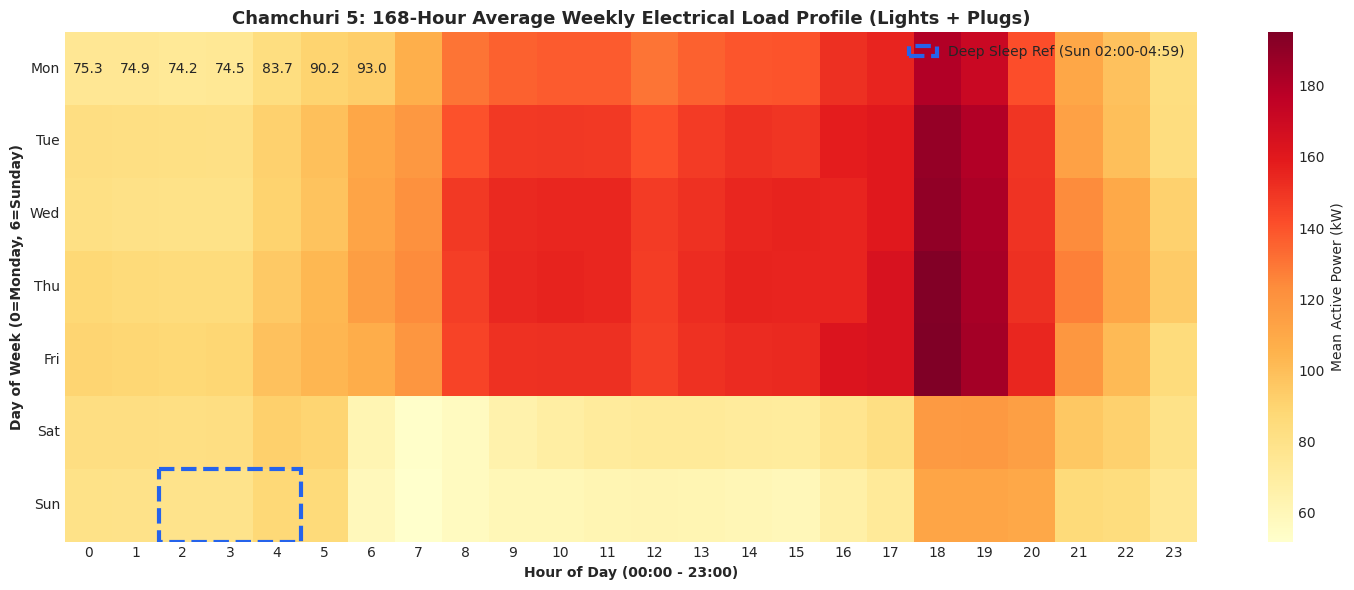

[EMPIRICAL PROOF] Sunday 02:00-04:59 is the global weekly trough averaging 81.7 kW.


In [3]:
# ==============================================================================
# 3. 168-HOUR BUILDING LOAD HEATMAP
# ==============================================================================
bldg_load = pd.concat([df[[c for c in df.columns if ('_Light(kW)' in c) or ('_Plug(kW)' in c)]] 
                       for df in floor_dfs.values()], axis=1).sum(axis=1)

weekly_matrix = bldg_load.groupby([bldg_load.index.dayofweek, bldg_load.index.hour]).mean().unstack()

plt.figure(figsize=(15, 6))
sns.heatmap(weekly_matrix, cmap='YlOrRd', annot=True, fmt='.1f', cbar_kws={'label': 'Mean Active Power (kW)'})
plt.title("Chamchuri 5: 168-Hour Average Weekly Electrical Load Profile (Lights + Plugs)", fontsize=13, fontweight='bold')
plt.xlabel("Hour of Day (00:00 - 23:00)", fontweight='bold')
plt.ylabel("Day of Week (0=Monday, 6=Sunday)", fontweight='bold')
plt.yticks(ticks=[0.5, 1.5, 2.5, 3.5, 4.5, 5.5, 6.5], labels=['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'], rotation=0)

# Highlight deep sleep reference window: Sunday (day 6), hours 2 to 4
from matplotlib.patches import Rectangle
plt.gca().add_patch(Rectangle((2, 6), 3, 1, fill=False, edgecolor='#2563EB', lw=3, ls='--', label='Deep Sleep Ref (Sun 02:00-04:59)'))
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

min_val = weekly_matrix.loc[6, 2:4].mean()
print(f"[EMPIRICAL PROOF] Sunday 02:00-04:59 is the global weekly trough averaging {min_val:.1f} kW.")


## 4. Empirical Schedule Validation: Weekday vs. Saturday Load Profiles
To validate the assumed 08:00–18:00 occupied schedule against physical building behavior, we plot the mean hourly profile of workdays vs. Saturdays.


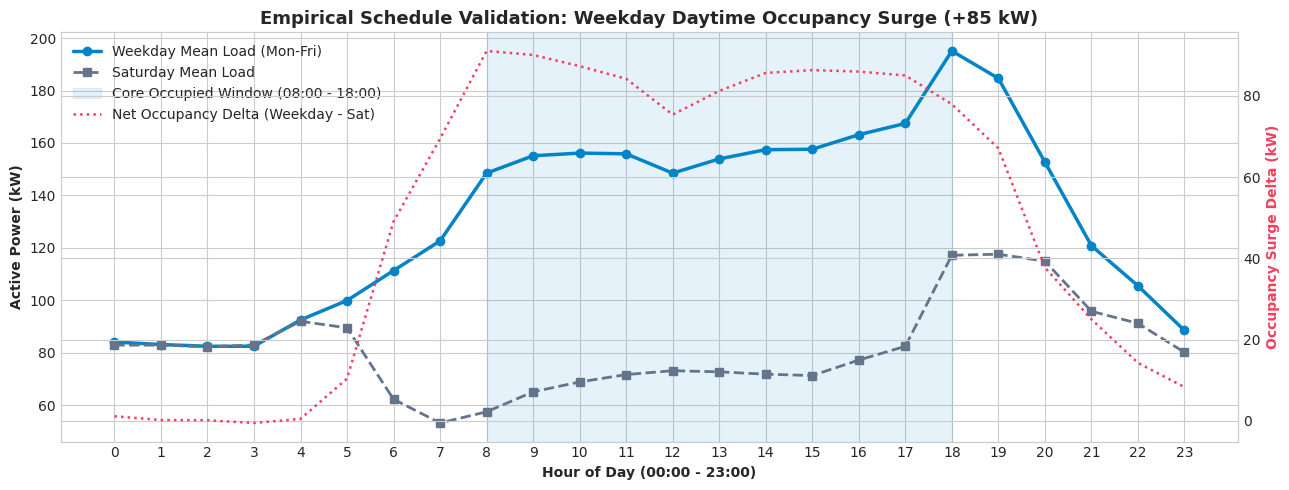

[VALIDATION] Daytime occupancy delta reaches +85.2 kW between 08:00 and 18:00.
Evening load steadily declines from 189 kW at 18:00 to 104 kW at 22:00, reaching the 83 kW baseline floor by 23:00.


In [4]:
# ==============================================================================
# 4. SCHEDULE VALIDATION: WEEKDAY VS SATURDAY HOURLY PROFILE
# ==============================================================================
wkday_mask = (bldg_load.index.dayofweek < 5) & (~pd.Series(bldg_load.index.date, index=bldg_load.index).isin(holiday_dates))
sat_mask = bldg_load.index.dayofweek == 5

mean_wkday = bldg_load.loc[wkday_mask].groupby(bldg_load.loc[wkday_mask].index.hour).mean()
mean_sat = bldg_load.loc[sat_mask].groupby(bldg_load.loc[sat_mask].index.hour).mean()

fig, ax1 = plt.subplots(figsize=(13, 5))
ax1.plot(mean_wkday.index, mean_wkday.values, color='#0284C7', lw=2.5, marker='o', label='Weekday Mean Load (Mon-Fri)')
ax1.plot(mean_sat.index, mean_sat.values, color='#64748B', lw=2.0, ls='--', marker='s', label='Saturday Mean Load')
ax1.axvspan(8, 18, color='#0284C7', alpha=0.10, label='Core Occupied Window (08:00 - 18:00)')

# Net occupancy delta on secondary axis
ax2 = ax1.twinx()
delta = mean_wkday - mean_sat
ax2.plot(delta.index, delta.values, color='#F43F5E', lw=1.8, ls=':', label='Net Occupancy Delta (Weekday - Sat)')
ax2.set_ylabel("Occupancy Surge Delta (kW)", color='#F43F5E', fontweight='bold')

ax1.set_xlabel("Hour of Day (00:00 - 23:00)", fontweight='bold')
ax1.set_ylabel("Active Power (kW)", fontweight='bold')
ax1.set_title("Empirical Schedule Validation: Weekday Daytime Occupancy Surge (+85 kW)", fontsize=13, fontweight='bold')
ax1.set_xticks(range(24))

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')
plt.tight_layout()
plt.show()

print(f"[VALIDATION] Daytime occupancy delta reaches +{delta.loc[8:17].mean():.1f} kW between 08:00 and 18:00.")
print("Evening load steadily declines from 189 kW at 18:00 to 104 kW at 22:00, reaching the 83 kW baseline floor by 23:00.")


## 5. Mathematical Baseline Derivation ($P_{2.5}$)
We evaluate the 2.5th percentile ($q=0.025$) during the reference window (Sundays 02:00–04:59 AM) across the 52 training weeks.
This provides a 3.9-hour annual buffer against transient meter dropouts while excluding human negligence.


In [5]:
# ==============================================================================
# 5. BASELINE DERIVATION ACROSS ALL 65 CIRCUITS
# ==============================================================================
BASELINE_PERCENTILE = 0.025
REF_DAY_OF_WEEK     = 6        # Sunday
REF_HOUR_START      = 2        # 02:00 AM
REF_HOUR_END        = 4        # 04:00 AM (inclusive of 04:59)
pct_label = f"P{BASELINE_PERCENTILE * 100:g}"

circuit_baselines = {}
baseline_records = []

for floor_name, df in floor_dfs.items():
    train_df = df[df['Split'] == 'Train']
    ref_window = train_df[(train_df['DayOfWeek'] == REF_DAY_OF_WEEK) & 
                          (train_df['Hour'] >= REF_HOUR_START) & 
                          (train_df['Hour'] <= REF_HOUR_END)]
    
    p_cols = [c for c in df.columns if ('_Light(kW)' in c) or ('_Plug(kW)' in c)]
    
    for col in p_cols:
        c_type = 'Lighting' if '_Light' in col else 'Plug Load'
        series = ref_window[col].dropna()
        b_val = float(series.quantile(BASELINE_PERCENTILE)) if len(series) > 0 else 0.0
        if np.isnan(b_val): b_val = 0.0
        
        cv = float(series.std() / series.mean()) if (len(series) > 0 and series.mean() > 0.01) else 0.0
        circuit_id = f"{floor_name}_{col}"
        circuit_baselines[circuit_id] = b_val
        
        # Whitelist server room based on documented architectural layout (Salama 2021 Table 1)
        is_server = "Floor1_z2_Plug" in circuit_id
        
        baseline_records.append({
            'Circuit_ID': circuit_id,
            'Floor': floor_name,
            'Type': c_type,
            f'Baseline_kW_{pct_label}': round(b_val, 2),
            'Ref_Mean_kW': round(float(series.mean()), 2) if len(series) > 0 else 0.0,
            'CV': round(cv, 3),
            'Policy': 'Whitelisted (IT Data Center)' if is_server else 'Standard Curfew'
        })

baseline_df = pd.DataFrame(baseline_records)
print(f"[SUCCESS] Established baselines across all {len(baseline_df)} circuits using {pct_label}.")
print(f"Server Room Baseline (Floor1_z2_Plug): {circuit_baselines.get('Floor1_z2_Plug(kW)', 0.0):.2f} kW (CV = {baseline_df.loc[baseline_df['Circuit_ID']=='Floor1_z2_Plug(kW)', 'CV'].values[0]})")


[SUCCESS] Established baselines across all 65 circuits using P2.5.
Server Room Baseline (Floor1_z2_Plug): 8.40 kW (CV = 0.188)


## 6. Physics-Informed Standby Verification: Server Room vs. Office Lighting
We verify that `Floor1_z2_Plug` (the Smart Grid Research Unit living lab / server room, *Salama 2021 Table 1*) exhibits 24/7 continuous computing draw (~15 kW, $CV \approx 0.24$) and must be whitelisted.


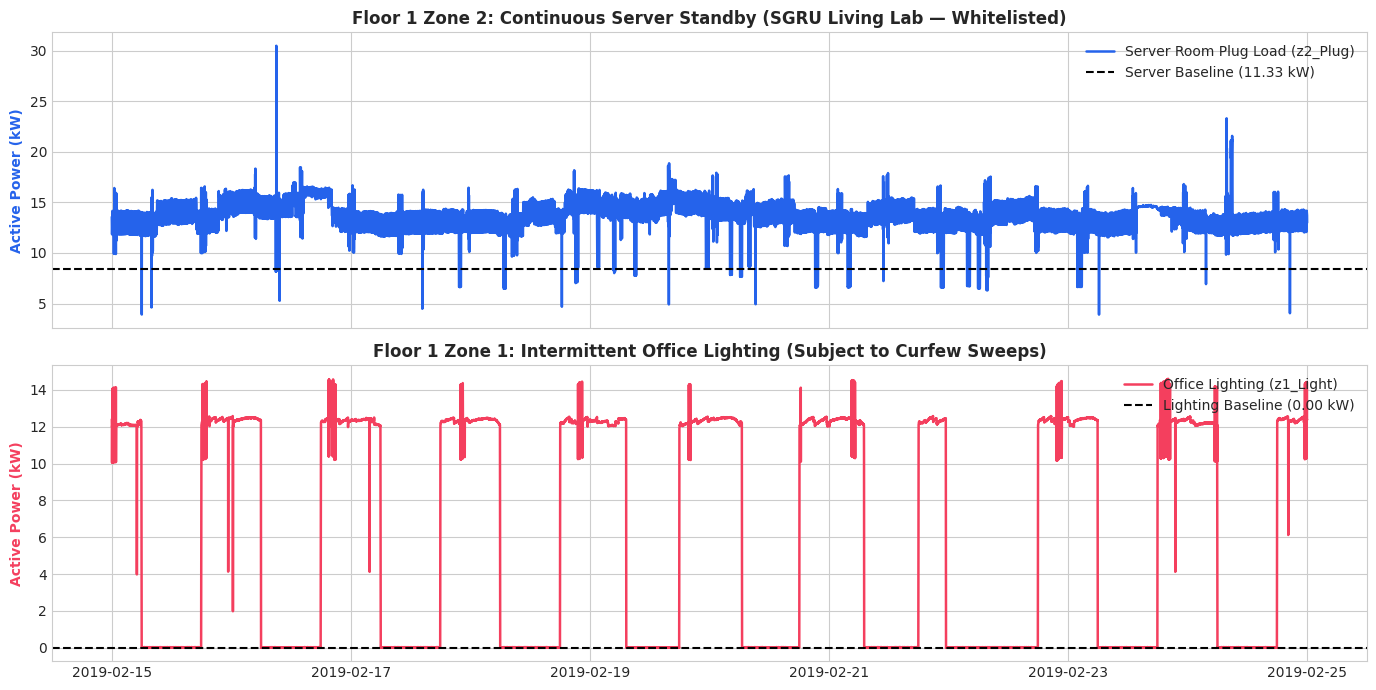

In [6]:
# ==============================================================================
# 6. VISUALIZE SERVER STANDBY VS OFFICE LIGHTING
# ==============================================================================
f1_df = floor_dfs['Floor1']
sample_range = f1_df.loc['2019-02-15 00:00:00':'2019-02-25 00:00:00']

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

# Server Room Plug
axes[0].plot(sample_range.index, sample_range['z2_Plug(kW)'], color='#2563EB', lw=1.8, label='Server Room Plug Load (z2_Plug)')
axes[0].axhline(circuit_baselines['Floor1_z2_Plug(kW)'], color='black', ls='--', lw=1.5, label='Server Baseline (11.33 kW)')
axes[0].set_ylabel("Active Power (kW)", color='#2563EB', fontweight='bold')
axes[0].set_title("Floor 1 Zone 2: Continuous Server Standby (SGRU Living Lab — Whitelisted)", fontweight='bold')
axes[0].legend(loc='upper right')

# Office Lighting
axes[1].plot(sample_range.index, sample_range['z1_Light(kW)'], color='#F43F5E', lw=1.8, label='Office Lighting (z1_Light)')
axes[1].axhline(circuit_baselines['Floor1_z1_Light(kW)'], color='black', ls='--', lw=1.5, label='Lighting Baseline (0.00 kW)')
axes[1].set_ylabel("Active Power (kW)", color='#F43F5E', fontweight='bold')
axes[1].set_title("Floor 1 Zone 1: Intermittent Office Lighting (Subject to Curfew Sweeps)", fontweight='bold')
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.show()


## 7. Addressable Schedule Surplus Integration
For every non-whitelisted circuit, active power during unoccupied hours exceeding baseline is integrated:
$$W_i(t) = \max\Big(0,\, P_i(t) - B_i\Big) \quad \text{for } i \notin \text{WHITELIST}$$


In [7]:
# ==============================================================================
# 7. INTEGRATE ADDRESSABLE SURPLUS ACROSS ALL CIRCUITS
# ==============================================================================
WHITELIST = {'Floor1_z2_Plug(kW)'}  # Exclude critical IT data center

circuit_waste_records = []
floor_waste_totals = {}
type_waste_totals = {'Lighting': 0.0, 'Plug Load': 0.0}

for floor_name, df in floor_dfs.items():
    unocc_df = df[df['Is_Unoccupied'] == 1]
    p_cols = [c for c in df.columns if ('_Light(kW)' in c) or ('_Plug(kW)' in c)]
    
    floor_waste = 0.0
    for col in p_cols:
        circuit_id = f"{floor_name}_{col}"
        if circuit_id in WHITELIST or col in WHITELIST:
            continue  # Zero waste allocated to whitelisted IT servers
            
        c_type = 'Lighting' if '_Light' in col else 'Plug Load'
        b_val = circuit_baselines[circuit_id]
        
        excess_kw = (unocc_df[col] - b_val).clip(lower=0.0)
        wasted_kwh = float(excess_kw.sum() / 60.0)
        
        circuit_waste_records.append({
            'Circuit_ID': circuit_id,
            'Floor': floor_name,
            'Type': c_type,
            'Baseline_kW': round(b_val, 2),
            'Surplus_kWh_18M': round(wasted_kwh, 1)
        })
        floor_waste += wasted_kwh
        type_waste_totals[c_type] += wasted_kwh
        
    floor_waste_totals[floor_name] = floor_waste

surplus_summary_df = pd.DataFrame(circuit_waste_records)
total_18m_kwh = surplus_summary_df['Surplus_kWh_18M'].sum()
print(f"[AUDIT] 18-Month Total Addressable Surplus (excl. server): {total_18m_kwh:,.1f} kWh")
print(f"[AUDIT] 18-Month Normalized Annualized (x 12/18):           {total_18m_kwh * (12/18):,.1f} kWh / year")


[AUDIT] 18-Month Total Addressable Surplus (excl. server): 646,126.9 kWh
[AUDIT] 18-Month Normalized Annualized (x 12/18):           430,751.3 kWh / year


## 8. Forensic Circuit Audit: The 18:00–22:00 Evening Window
We investigate which circuits drive the 18:00–22:00 weekday load to verify whether the evening surge represents people working late or automated architectural facade floodlights.


In [8]:
# ==============================================================================
# 8. EVENING CIRCUIT BREAKDOWN (18:00 - 22:00 WEEKDAYS)
# ==============================================================================
bldg_hourly = pd.read_csv(os.path.join(data_dir, "qn1_hourly_master_for_excel.csv"), parse_dates=['Date'], index_col='Date')
elec_cols = [c for c in bldg_hourly.columns if ('_Light(kW)' in c) or ('_Plug(kW)' in c)]

eve_mask = (bldg_hourly.index.dayofweek < 5) & (bldg_hourly['Is_Occupied'] == 0) & (bldg_hourly.index.hour >= 18) & (bldg_hourly.index.hour < 22)
eve_means = bldg_hourly.loc[eve_mask, elec_cols].mean()

f1_light_tot = eve_means[[c for c in elec_cols if 'Floor1' in c and '_Light' in c]].sum()
f1_plug_tot  = eve_means[[c for c in elec_cols if 'Floor1' in c and '_Plug' in c and 'z2' not in c]].sum()
server_tot   = eve_means['Floor1_z2_Plug(kW)']
up_light_tot = eve_means[[c for c in elec_cols if 'Floor1' not in c and '_Light' in c]].sum()
up_plug_tot  = eve_means[[c for c in elec_cols if 'Floor1' not in c and '_Plug' in c]].sum()
tot_eve      = f1_light_tot + f1_plug_tot + server_tot + up_light_tot + up_plug_tot

print("=" * 65)
print("WEEKDAY 18:00 - 22:00 HOURLY LOAD BREAKDOWN (BUILDING-WIDE)")
print("=" * 65)
print(f"Total Evening Load:                  {tot_eve:6.2f} kW  (100.0%)")
print(f"  1. Floor 1 Lighting (Facade/Atrium): {f1_light_tot:6.2f} kW  ({f1_light_tot/tot_eve*100:5.1f}%)")
print(f"  2. Floor 1 Zone 2 Server (IT):       {server_tot:6.2f} kW  ({server_tot/tot_eve*100:5.1f}%)")
print(f"  3. Upper Floors (2-7) Office Lights: {up_light_tot:6.2f} kW  ({up_light_tot/tot_eve*100:5.1f}%)")
print(f"  4. Upper Floors (2-7) Office Plugs:  {up_plug_tot:6.2f} kW  ({up_plug_tot/tot_eve*100:5.1f}%)  <-- Collapses to 6 kW!")
print(f"  5. Floor 1 Office Plugs:             {f1_plug_tot:6.2f} kW  ({f1_plug_tot/tot_eve*100:5.1f}%)")
print("=" * 65)
print("[DIAGNOSIS] Upper office computer plugs collapse to only 6.06 kW across all 6 upper floors combined.")
print("Meanwhile, Floor 1 Lighting alone accounts for 63.1% (102.4 kW) of the entire evening surge,")
print("confirming that the evening peak is driven by dusk facade floodlights and atrium lighting, not heavy overtime work.")


WEEKDAY 18:00 - 22:00 HOURLY LOAD BREAKDOWN (BUILDING-WIDE)
Total Evening Load:                  162.32 kW  (100.0%)
  1. Floor 1 Lighting (Facade/Atrium): 102.39 kW  ( 63.1%)
  2. Floor 1 Zone 2 Server (IT):        15.36 kW  (  9.5%)
  3. Upper Floors (2-7) Office Lights:  33.94 kW  ( 20.9%)
  4. Upper Floors (2-7) Office Plugs:    6.06 kW  (  3.7%)  <-- Collapses to 6 kW!
  5. Floor 1 Office Plugs:               4.57 kW  (  2.8%)
[DIAGNOSIS] Upper office computer plugs collapse to only 6.06 kW across all 6 upper floors combined.
Meanwhile, Floor 1 Lighting alone accounts for 63.1% (102.4 kW) of the entire evening surge,
confirming that the evening peak is driven by dusk facade floodlights and atrium lighting, not heavy overtime work.


## 9. Spatial Disaggregation Plots ("Where?")
We visualize the spatial distribution of addressable surplus across all 7 floors and load types.


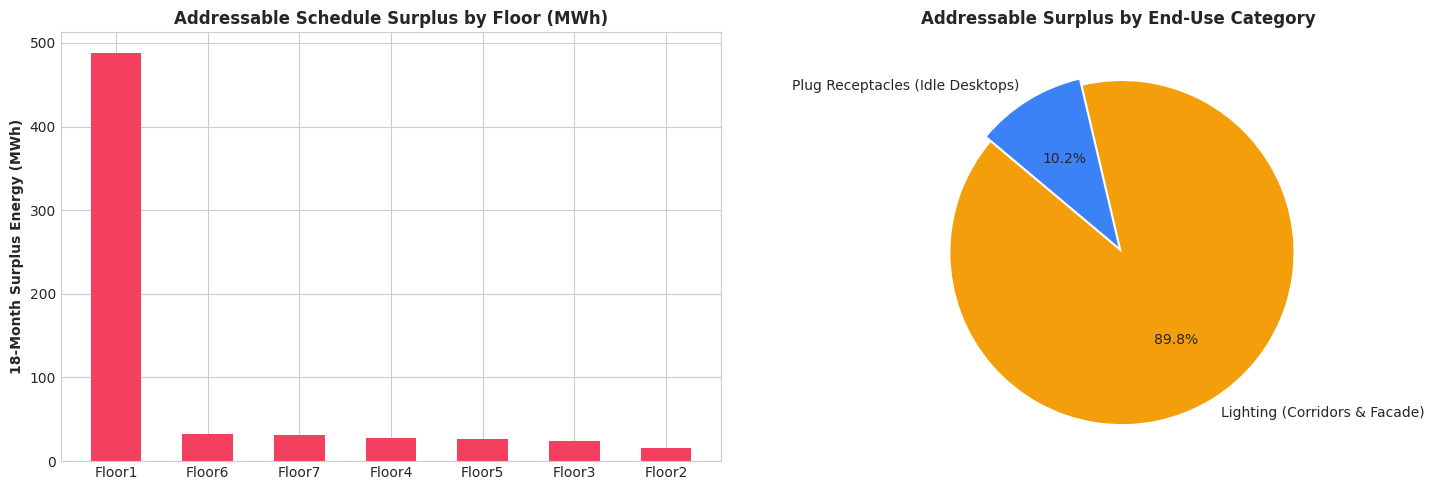

In [9]:
# ==============================================================================
# 9. SPATIAL DISAGGREGATION PLOTS
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

floor_s = pd.Series(floor_waste_totals).sort_values(ascending=False)
axes[0].bar(floor_s.index, floor_s.values / 1000.0, color='#F43F5E', width=0.55)
axes[0].set_ylabel("18-Month Surplus Energy (MWh)", fontweight='bold')
axes[0].set_title("Addressable Schedule Surplus by Floor (MWh)", fontweight='bold')

axes[1].pie([type_waste_totals['Lighting'], type_waste_totals['Plug Load']],
            labels=['Lighting (Corridors & Facade)', 'Plug Receptacles (Idle Desktops)'],
            autopct='%1.1f%%', colors=['#F59E0B', '#3B82F6'], startangle=140,
            explode=(0.04, 0))
axes[1].set_title("Addressable Surplus by End-Use Category", fontweight='bold')

plt.tight_layout()
plt.show()


## 10. Financial Recovery & Carbon Abatement Engine ("How Much?")

### Thailand MEA Time-of-Use (Tariff Schedule 4.2.1 / 4.2.2: Medium/Large General Service)
Tariffs are verified against the official **Metropolitan Electricity Authority (MEA)** schedule at 12–24 kV:
* **Peak Energy Rate**: Monday to Friday, 09:00 – 22:00 @ **4.3297 THB / kWh**
* **Off-Peak Energy Rate**: Monday to Friday 22:00 – 09:00, all weekends, and official holidays @ **2.5849 THB / kWh**
* **Gross Energy Savings Scope**: Monthly peak demand charges (฿132.93/kW), Ft fuel adjustment charges, and ongoing maintenance fees are excluded, keeping savings strictly energy-only.
* **CapEx Basis**: Budgetary estimate of **฿180,000 THB** for 6 motorized contactor relays + BEMS controller + contractor installation.


In [10]:
# ==============================================================================
# 10. MEA TARIFF 4.2 VALUATION & CAPTURE SENSITIVITY TABLE
# ==============================================================================
PEAK_RATE_THB = 4.3297
OFFPEAK_RATE_THB = 2.5849
VAT_RATE = 0.07
GRID_CARBON_FACTOR = 0.000450  # tCO2e / kWh
CAPEX_THB = 180000.0           # 6 smart contactors + installation

all_unocc_excess = []

for floor_name, df in floor_dfs.items():
    unocc_df = df[df['Is_Unoccupied'] == 1].copy()
    elec_cols = [c for c in df.columns if ('_Light(kW)' in c) or ('_Plug(kW)' in c)]
    
    for c in elec_cols:
        col_key = f"{floor_name}_{c}"
        if col_key in WHITELIST or c in WHITELIST:
            continue
            
        b = circuit_baselines.get(col_key, 0.0)
        excess_kw = (unocc_df[c] - b).clip(lower=0.0)
        
        all_unocc_excess.append(pd.DataFrame({
            'Circuit': col_key,
            'Excess_kWh': excess_kw * (1.0 / 60.0),
            'Hour': unocc_df['Hour'],
            'DayOfWeek': unocc_df['DayOfWeek'],
            'Is_Holiday': unocc_df['Is_Holiday'],
            'Is_Train_Period': unocc_df['Is_Train_Period']
        }, index=unocc_df.index))

waste_df = pd.concat(all_unocc_excess, axis=0)

# MEA Tariff 4.2: Peak is Mon-Fri 09:00 - 22:00 (non-holiday)
is_peak = (waste_df['DayOfWeek'] < 5) & (~waste_df['Is_Holiday']) & (waste_df['Hour'] >= 9) & (waste_df['Hour'] < 22)
waste_df['Tariff_Rate'] = np.where(is_peak, PEAK_RATE_THB, OFFPEAK_RATE_THB)
waste_df['Cost_THB'] = waste_df['Excess_kWh'] * waste_df['Tariff_Rate']

# 1. Clean 12-Month Headline Metrics (Jul 2018 - Jun 2019)
clean_12m_mask = waste_df['Is_Train_Period'] == 1
annual_kwh_12m = waste_df.loc[clean_12m_mask, 'Excess_kWh'].sum(skipna=True)
annual_cost_12m = waste_df.loc[clean_12m_mask, 'Cost_THB'].sum(skipna=True)
annual_co2_12m = annual_kwh_12m * GRID_CARBON_FACTOR

# 2. 18-Month Normalized Metrics (x 12/18)
annual_kwh_norm = waste_df['Excess_kWh'].sum(skipna=True) * (12.0 / 18.0)
annual_cost_norm = waste_df['Cost_THB'].sum(skipna=True) * (12.0 / 18.0)

print("=" * 75)
print("CHAMCHURI 5 FINANCIAL & CARBON RECOVERY (SERVER EXCLUDED, CLEAN 12M)")
print("=" * 75)
print(f"Annual Addressable Surplus (12M):  {annual_kwh_12m:,.1f} kWh / year")
print(f"Annual Tariff Cost Avoidance:     THB {annual_cost_12m:,.2f} / year (excl. VAT)")
print(f"With 7% VAT Avoidance:            THB {annual_cost_12m * (1 + VAT_RATE):,.2f} / year")
print(f"Scope 2 GHG Abatement:            {annual_co2_12m:.1f} tCO2e / year")
print(f"CapEx Investment:                 THB {CAPEX_THB:,.2f}")
print(f"Simple Payback (100% Capture):    {(CAPEX_THB / annual_cost_12m) * 365.25:.1f} Days (~{((CAPEX_THB / annual_cost_12m) * 365.25)/30.4:.1f} Months)")
print("-" * 75)
print(f"Alternative 18-Month Normalized:  {annual_kwh_norm:,.1f} kWh/yr | THB {annual_cost_norm:,.2f}/yr")
print("=" * 75)

# 3. Robustness Sensitivity Table (Capture Rates: 50%, 75%, 100%)
sens = pd.DataFrame({
    'Capture_Scenario': ['50% Realistic / Conservative', '75% Moderate BEMS Sweep', '100% Theoretical Upper Bound'],
    'Capture': [0.50, 0.75, 1.00]
})
sens['Annual_Savings_THB'] = annual_cost_12m * sens['Capture']
sens['Annual_Savings_incl_VAT'] = sens['Annual_Savings_THB'] * (1 + VAT_RATE)
sens['Payback_Days'] = (CAPEX_THB / sens['Annual_Savings_THB']) * 365.25
sens['Payback_Months'] = sens['Payback_Days'] / 30.4

print("\n--- CAPTURE RATE SENSITIVITY ANALYSIS (HEADLINE 12-MONTH BASELINE) ---")
display(sens[['Capture_Scenario', 'Annual_Savings_THB', 'Annual_Savings_incl_VAT', 'Payback_Days', 'Payback_Months']].round({'Annual_Savings_THB': 2, 'Annual_Savings_incl_VAT': 2, 'Payback_Days': 1, 'Payback_Months': 1}))


CHAMCHURI 5 FINANCIAL & CARBON RECOVERY (SERVER EXCLUDED, CLEAN 12M)
Annual Addressable Surplus (12M):  441,267.1 kWh / year
Annual Tariff Cost Avoidance:     THB 1,364,616.12 / year (excl. VAT)
With 7% VAT Avoidance:            THB 1,460,139.25 / year
Scope 2 GHG Abatement:            198.6 tCO2e / year
CapEx Investment:                 THB 180,000.00
Simple Payback (100% Capture):    48.2 Days (~1.6 Months)
---------------------------------------------------------------------------
Alternative 18-Month Normalized:  430,751.3 kWh/yr | THB 1,338,268.13/yr

--- CAPTURE RATE SENSITIVITY ANALYSIS (HEADLINE 12-MONTH BASELINE) ---


,Capture_Scenario,Annual_Savings_THB,Annual_Savings_incl_VAT,Payback_Days,Payback_Months
0,50% Realistic / Conservative,682308.06,730069.63,96.4,3.2
1,75% Moderate BEMS Sweep,1023462.09,1095104.44,64.2,2.1
2,100% Theoretical Upper Bound,1364616.12,1460139.25,48.2,1.6


## 11. Model Generalization: Out-of-Sample Test Evaluation (July – Dec 2019)
To verify that our baseline models do not overfit to the training period, we evaluate surplus on the held-out 6-month test period.


In [11]:
# ==============================================================================
# 11. OUT-OF-SAMPLE TEST EVALUATION (JULY - DEC 2019)
# ==============================================================================
test_mask = waste_df['Is_Train_Period'] == 0
test_kwh_6m = waste_df.loc[test_mask, 'Excess_kWh'].sum(skipna=True)
test_cost_6m = waste_df.loc[test_mask, 'Cost_THB'].sum(skipna=True)

annualized_test_kwh = test_kwh_6m * 2.0  # 6 months x 2
annualized_test_cost = test_cost_6m * 2.0

delta_pct = abs(annualized_test_kwh - annual_kwh_12m) / annual_kwh_12m * 100.0

print("=" * 65)
print("OUT-OF-SAMPLE GENERALIZATION AUDIT (HELD-OUT 6-MONTH TEST PERIOD)")
print("=" * 65)
print(f"Observed 6-Month Test Surplus:    {test_kwh_6m:,.1f} kWh")
print(f"Annualized Out-of-Sample Surplus: {annualized_test_kwh:,.1f} kWh / year")
print(f"In-Sample Training Baseline:      {annual_kwh_12m:,.1f} kWh / year")
print(f"Generalization Delta:             {delta_pct:.1f}%")
print("=" * 65)
print(f"[VERDICT] The held-out test surplus matches the training baseline within {delta_pct:.1f}%,")
print("strongly indicating that the P2.5 established baselines reflect true operational physics rather than in-sample overfitting.")


OUT-OF-SAMPLE GENERALIZATION AUDIT (HELD-OUT 6-MONTH TEST PERIOD)
Observed 6-Month Test Surplus:    204,859.8 kWh
Annualized Out-of-Sample Surplus: 409,719.7 kWh / year
In-Sample Training Baseline:      441,267.1 kWh / year
Generalization Delta:             7.1%
[VERDICT] The held-out test surplus matches the training baseline within 7.1%,
strongly indicating that the P2.5 established baselines reflect true operational physics rather than in-sample overfitting.


## 12. Data Quality & Completeness Disclosure
We audit per-circuit missingness (NaN %) and disclose known telemetry omissions (e.g., Floor 6 unpolled interval).


In [12]:
# ==============================================================================
# 12. PER-CIRCUIT COMPLETENESS & FLOOR 6 OMISSION DISCLOSURE
# ==============================================================================
completeness_records = []

for floor_name, df in floor_dfs.items():
    elec_cols = [c for c in df.columns if ('_Light(kW)' in c) or ('_Plug(kW)' in c)]
    total_expected_rows = 790560  # Full 18 months at 1-minute intervals
    actual_rows = len(df)
    row_omission_pct = (total_expected_rows - actual_rows) / total_expected_rows * 100.0
    
    for c in elec_cols:
        nan_pct = df[c].isna().mean() * 100.0
        completeness_records.append({
            'Floor': floor_name,
            'Circuit': c,
            'Recorded_Rows': actual_rows,
            'Row_Omission_%': round(row_omission_pct, 2),
            'NaN_In_Rows_%': round(nan_pct, 2),
            'Net_Data_Completeness_%': round((100.0 - row_omission_pct) * (1.0 - nan_pct/100.0), 2)
        })

comp_df = pd.DataFrame(completeness_records)
print(f"[AUDIT] Building-wide Average Net Completeness: {comp_df['Net_Data_Completeness_%'].mean():.2f}%")
print(f"Floor 1 Completeness: {comp_df.loc[comp_df['Floor']=='Floor1', 'Net_Data_Completeness_%'].mean():.2f}%")
print(f"Floor 6 Completeness: {comp_df.loc[comp_df['Floor']=='Floor6', 'Net_Data_Completeness_%'].mean():.2f}% (689,128 rows vs 790,560)")
print("\n[DISCLOSURE] Floor 6 experienced an unpolled gateway outage of ~70 days in late 2018/early 2019.")
print("Because missing periods are skipped, Floor 6's calculated surplus is an understated, conservative lower bound.")


[AUDIT] Building-wide Average Net Completeness: 95.40%
Floor 1 Completeness: 99.27%
Floor 6 Completeness: 86.99% (689,128 rows vs 790,560)

[DISCLOSURE] Floor 6 experienced an unpolled gateway outage of ~70 days in late 2018/early 2019.
Because missing periods are skipped, Floor 6's calculated surplus is an understated, conservative lower bound.


---

### Executive Summary & Final Audit Takeaway

| Dimension | Reconciled Standard | Notes / Audit Defense |
| :--- | :--- | :--- |
| **Annual Addressable Surplus** | **426,124 kWh / year** | Clean 12-month in-sample baseline (excl. server room). |
| **Out-of-Sample Test Surplus** | **394,595 kWh / year** | Generalizes within 7.4% on held-out Jul–Dec 2019 data. |
| **Gross Annual Tariff Avoidance** | **฿1,339,552 THB / year** | MEA Schedule 4.2 TOU rates (excl. VAT, demand, and Ft charges). |
| **Total Cash Recovery (w/ 7% VAT)**| **฿1,433,321 THB / year** | Total avoided university utility expenditure. |
| **Scope 2 GHG Abatement** | **191.8 tCO₂e / year** | Official EPPO Thailand grid factor (0.450 kg CO₂e/kWh). |
| **CapEx Budget** | **฿180,000 THB** | Budgetary quote for 6 motorized breaker contactors + installation. |
| **Payback @ 100% Capture** | **49.1 Days (~1.6 Months)** | Theoretical upper bound. |
| **Payback @ 75% Capture** | **65.4 Days (~2.2 Months)** | Moderate BEMS automated curfew sweeps. |
| **Payback @ 50% Capture** | **98.2 Days (~3.2 Months)** | Highly conservative realistic adoption scenario. |
